# Volatility Surface

## 1. Goal

Plot implied volatility surface of strike and maturity and learn 

- smile vs skew

- term structure

- volatility surface

In [1]:
# # Download AAPL option data 
# # Historical data has been downloaded and saved locally.
# # No need to run this cell again unless updating the dataset.

# %load_ext autoreload
# %autoreload 2
# import src.data_loader as data_loader

# options=data_loader.download_option_data(proxy='http://127.0.0.1:7897')
# print(options.head())



In [2]:
# # Determine S0, q and r
# # Once determind S0, q and r, save to csv files, no need to run this cell
%load_ext autoreload
%autoreload 2
from pathlib import Path
import src.data_loader as data_loader
import pandas as pd 
import yfinance as yf 
yf.config.network.proxy='http://127.0.0.1:7897'

# Create a fresh ticker object
ticker=yf.Ticker('AAPL')

# Download intraday data
stock_data=ticker.history(
    start='2026-11-06',end='2026-11-07',interval='1m',prepost=False,auto_adjust=False
)

# Removing missing observations
stock_data=stock_data.dropna(subset=['Close'])

# Get the latest completed minute
if stock_data.empty:
    raise ValueError('No stock data available for the selected date.')


display(stock_data.tail())

info=ticker.get_info()

fields=[
    'regularMarketPrice',
    'regularMarketTime',
    'bid',
    'ask',
    'bidSize',
    'askSize',
    'marketState'
]

for field in fields:
    print(field,':',info.get(field))

S0=342.37

dividend_rate=info.get('dividendRate')
dividend_yield=info.get('dividendYield')

if dividend_rate is not None:
    q=dividend_rate/S0
else:
    q=dividend_yield

print('\nAnnual dividend:',dividend_rate)
print('Dividend yield:',q)

# Determine S0, q based on downloaded data
S0=342.37;annual_dividend=1.08;q=0.00315

# Calculate risk free rate
treasury_path=Path.cwd()/'data'/'raw'/'daily-treasury-rates_20261106.csv'
valuation_date='2026-11-06'
SELECTED_EXPIRATIONS=[
    '2026-11-27',
    '2026-12-04',
    '2026-12-11',
    '2026-12-18',
    '2027-01-15',
    '2027-02-19',
    '2027-03-19',
    '2027-04-16',
    '2027-06-17',
    '2027-09-17',
    '2027-12-17',
    '2028-01-21',
    '2028-03-17',
    '2028-06-16',
    '2028-12-15',
    '2029-01-19',
]
risk_free_rate=data_loader.get_risk_free_rate(treasury_path,SELECTED_EXPIRATIONS,valuation_date)

print('\nRisk free rate')
print(risk_free_rate)

risk_free_rate.to_csv(Path.cwd()/'data'/'raw'/'risk_free_rate_20261106.csv',index=False)

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,,
2026-11-06 15:55:00-05:00,342.529999,343.070007,342.450012,342.855011,342.855011,196598,0.0,0.0
2026-11-06 15:56:00-05:00,342.829987,342.950012,342.559998,342.679993,342.679993,113949,0.0,0.0
2026-11-06 15:57:00-05:00,342.690002,342.690002,342.339996,342.450012,342.450012,192544,0.0,0.0
2026-11-06 15:58:00-05:00,342.459991,342.630005,342.260010,342.420013,342.420013,313586,0.0,0.0
2026-11-06 15:59:00-05:00,342.420013,342.670013,342.290009,342.364990,342.364990,647051,0.0,0.0


regularMarketPrice : 342.37
regularMarketTime : 1793998801
bid : 342.02
ask : 344.97
bidSize : 4
askSize : 4
marketState : CLOSED

Annual dividend: None
Dividend yield: None

Risk free rate
    expiration  days         T         r
0   2026-11-27    21  0.057534  0.039801
1   2026-12-04    28  0.076712  0.039801
2   2026-12-11    35  0.095890  0.039949
3   2026-12-18    42  0.115068  0.040175
4   2027-01-15    70  0.191781  0.041193
5   2027-02-19   105  0.287671  0.041467
6   2027-03-19   133  0.364384  0.041540
7   2027-04-16   161  0.441096  0.041720
8   2027-06-17   223  0.610959  0.042076
9   2027-09-17   315  0.863014  0.042570
10  2027-12-17   406  1.112329  0.043036
11  2028-01-21   441  1.208219  0.043205
12  2028-03-17   497  1.361644  0.043475
13  2028-06-16   588  1.610959  0.043914
14  2028-12-15   770  2.109589  0.044685
15  2029-01-19   805  2.205479  0.044760


In [3]:
S0=342.37;annual_dividend=1.08;q=0.00315

data=pd.read_csv('data/raw/AAPL_options_20261106.csv')
risk_free_rate=pd.read_csv('data/raw/risk_free_rate_20261106.csv')

# Data cleaning 
import src.data_cleaning as data_cleaning
clean_options,otm_options=data_cleaning.clean_option_data(
    data,risk_free_rate,S0=342.37,q=0.00315
)

# Data framework 
print('Original:',data.shape)
print('Cleaned:',clean_options.shape)
print('OTM:',otm_options.shape)

display(otm_options.head())

print(clean_options['relative_spread'].describe())

print(otm_options.groupby(['expiration','option_type']).size())

# Save cleaned data to csv
PROCESSED_DIR=Path.cwd()/'data'/'processed'
PROCESSED_DIR.mkdir(exist_ok=True)

clean_options.to_csv(PROCESSED_DIR/'AAPL_options_clean_20261106.csv',index=False)
otm_options.to_csv(PROCESSED_DIR/'AAPL_options_otm_20261106.csv',index=False)



Original: (2152, 17)
Cleaned: (1945, 27)
OTM: (984, 27)


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,...,mid_price,spread_price,relative_spread,T,r,S0,q,forward_price,moneyness,log_moneyness
33,AAPL261127C00345000,2026-11-06 20:55:34+00:00,345.0,7.65,7.30,7.60,-1.62,-17.475730,232.0,1783,...,7.450,0.30,0.040268,0.057534,0.039801,342.37,0.00315,343.09272,1.005559,0.005544
34,AAPL261127C00350000,2026-11-06 20:59:47+00:00,350.0,5.20,5.00,5.25,-1.50,-22.388060,489.0,1483,...,5.125,0.25,0.048780,0.057534,0.039801,342.37,0.00315,343.09272,1.020132,0.019932
35,AAPL261127C00355000,2026-11-06 20:56:52+00:00,355.0,3.44,3.25,3.50,-1.76,-33.846150,820.0,1913,...,3.375,0.25,0.074074,0.057534,0.039801,342.37,0.00315,343.09272,1.034706,0.034117
36,AAPL261127C00360000,2026-11-06 20:55:23+00:00,360.0,2.09,2.01,2.17,-0.91,-30.333336,396.0,1460,...,2.090,0.16,0.076555,0.057534,0.039801,342.37,0.00315,343.09272,1.049279,0.048103
37,AAPL261127C00365000,2026-11-06 20:59:30+00:00,365.0,1.23,1.15,1.30,-0.83,-40.291260,263.0,1331,...,1.225,0.15,0.122449,0.057534,0.039801,342.37,0.00315,343.09272,1.063852,0.061897


count    1945.000000
mean        0.259041
std         0.470205
min         0.008149
25%         0.021448
50%         0.045163
75%         0.197183
max         1.986928
Name: relative_spread, dtype: float64
expiration  option_type
2026-11-27  call           15
            put            30
2026-12-04  call           15
            put            27
2026-12-11  call           15
            put            24
2026-12-18  call           20
            put            36
2027-01-15  call           29
            put            37
2027-02-19  call           26
            put            32
2027-03-19  call           26
            put            34
2027-04-16  call           22
            put            30
2027-06-17  call           25
            put            43
2027-09-17  call           30
            put            51
2027-12-17  call           33
            put            60
2028-01-21  call           25
            put            38
2028-03-17  call           24
            put     

In [4]:
import src.implied_volatility as iv 

# Calculate implied volatility
clean_options=pd.read_csv(r'data\processed\AAPL_options_clean_20261106.csv')
otm_options=pd.read_csv(r'data\processed\AAPL_options_otm_20261106.csv')

iv_data=iv.calculate_iv_surface(clean_options,max_spread=0.3)

display(
    iv_data[
        [
            'expiration',
            'option_type',
            'T',
            'strike',
            'mid_price',
            'iv_yahoo',
            'iv_bs'
        ]
    ].head(10)
)

print(iv_data.groupby(['expiration','option_type']).size())

iv_data['iv_difference']=iv_data['iv_bs']-iv_data['iv_yahoo']

print(iv_data[['iv_bs','iv_yahoo','iv_difference']].describe())

Contracts after spread filtering: 1545
Sucessful IV calculations: 1521
Success rate: 98.45%


,expiration,option_type,T,strike,mid_price,iv_yahoo,iv_bs
0,2026-11-27,call,0.057534,130.0,212.700,1.761720,1.526443
1,2026-11-27,call,0.057534,145.0,197.825,1.646486,1.470183
2,2026-11-27,call,0.057534,165.0,177.825,1.417972,1.222364
3,2026-11-27,call,0.057534,170.0,172.775,1.342777,1.103488
4,2026-11-27,call,0.057534,175.0,167.800,1.302738,1.079165
5,2026-11-27,call,0.057534,190.0,152.825,1.166996,0.945358
6,2026-11-27,call,0.057534,210.0,133.000,1.040044,0.891668
7,2026-11-27,call,0.057534,215.0,127.925,0.975586,0.799050
8,2026-11-27,call,0.057534,220.0,122.950,0.939942,0.772772
9,2026-11-27,call,0.057534,225.0,118.200,0.954590,0.843873


expiration  option_type
2026-11-27  call            40
            put             26
2026-12-04  call            30
            put             21
2026-12-11  call            19
            put             13
2026-12-18  call            70
            put             42
2027-01-15  call            78
            put             43
2027-02-19  call            53
            put             25
2027-03-19  call            53
            put             31
2027-04-16  call            48
            put             43
2027-06-17  call            68
            put             37
2027-09-17  call            77
            put             56
2027-12-17  call           101
            put             68
2028-01-21  call            73
            put             46
2028-03-17  call            46
            put             34
2028-06-16  call            55
            put             30
2028-12-15  call            68
            put             43
2029-01-19  call            72
            put

In [5]:
# Threshold sampling
thresholds=[0.1,0.15,0.2,0.3]
otm_iv=iv.calculate_iv_surface(otm_options)

for threshold in thresholds:
    subset=otm_iv[
        otm_iv['relative_spread']<=threshold
    ]
    print(f'\nSpread threshold: {threshold:.0%}')

    summary=subset.groupby('expiration').agg(
        n=('iv_bs','count'),
        iv_median=('iv_bs','median'),
        iv_max=('iv_bs','max')
    )
    display(summary)

Contracts after spread filtering: 584
Sucessful IV calculations: 584
Success rate: 100.00%

Spread threshold: 10%


,n,iv_median,iv_max
expiration,,,
2026-11-27,14,0.300754,0.431628
2026-12-04,2,0.272577,0.282775
2026-12-11,1,0.260784,0.260784
2026-12-18,23,0.283352,0.404325
2027-01-15,28,0.277678,0.385440
2027-02-19,17,0.288653,0.385562
2027-03-19,20,0.283932,0.385831
2027-04-16,37,0.287346,0.371896
2027-06-17,24,0.282553,0.370447



Spread threshold: 15%


,n,iv_median,iv_max
expiration,,,
2026-11-27,15,0.294382,0.431628
2026-12-04,8,0.261560,0.440110
2026-12-11,4,0.244646,0.260784
2026-12-18,28,0.287754,0.459656
2027-01-15,31,0.280979,0.405008
2027-02-19,18,0.283867,0.385562
2027-03-19,23,0.287863,0.448410
2027-04-16,41,0.287346,0.383366
2027-06-17,30,0.287244,0.407015



Spread threshold: 20%


,n,iv_median,iv_max
expiration,,,
2026-11-27,17,0.294382,0.431628
2026-12-04,12,0.285876,0.440110
2026-12-11,8,0.253297,0.347977
2026-12-18,31,0.301440,0.517501
2027-01-15,34,0.284466,0.425500
2027-02-19,20,0.283867,0.401192
2027-03-19,24,0.292204,0.448410
2027-04-16,45,0.291202,0.406278
2027-06-17,31,0.284670,0.407015



Spread threshold: 30%


,n,iv_median,iv_max
expiration,,,
2026-11-27,19,0.294382,0.451067
2026-12-04,16,0.285876,0.440110
2026-12-11,18,0.264348,0.376480
2026-12-18,33,0.311490,0.517501
2027-01-15,37,0.287953,0.446418
2027-02-19,22,0.293608,0.434950
2027-03-19,27,0.296545,0.465914
2027-04-16,47,0.295333,0.422771
2027-06-17,37,0.284670,0.431414


Contracts after spread filtering: 584
Sucessful IV calculations: 584
Success rate: 100.00%


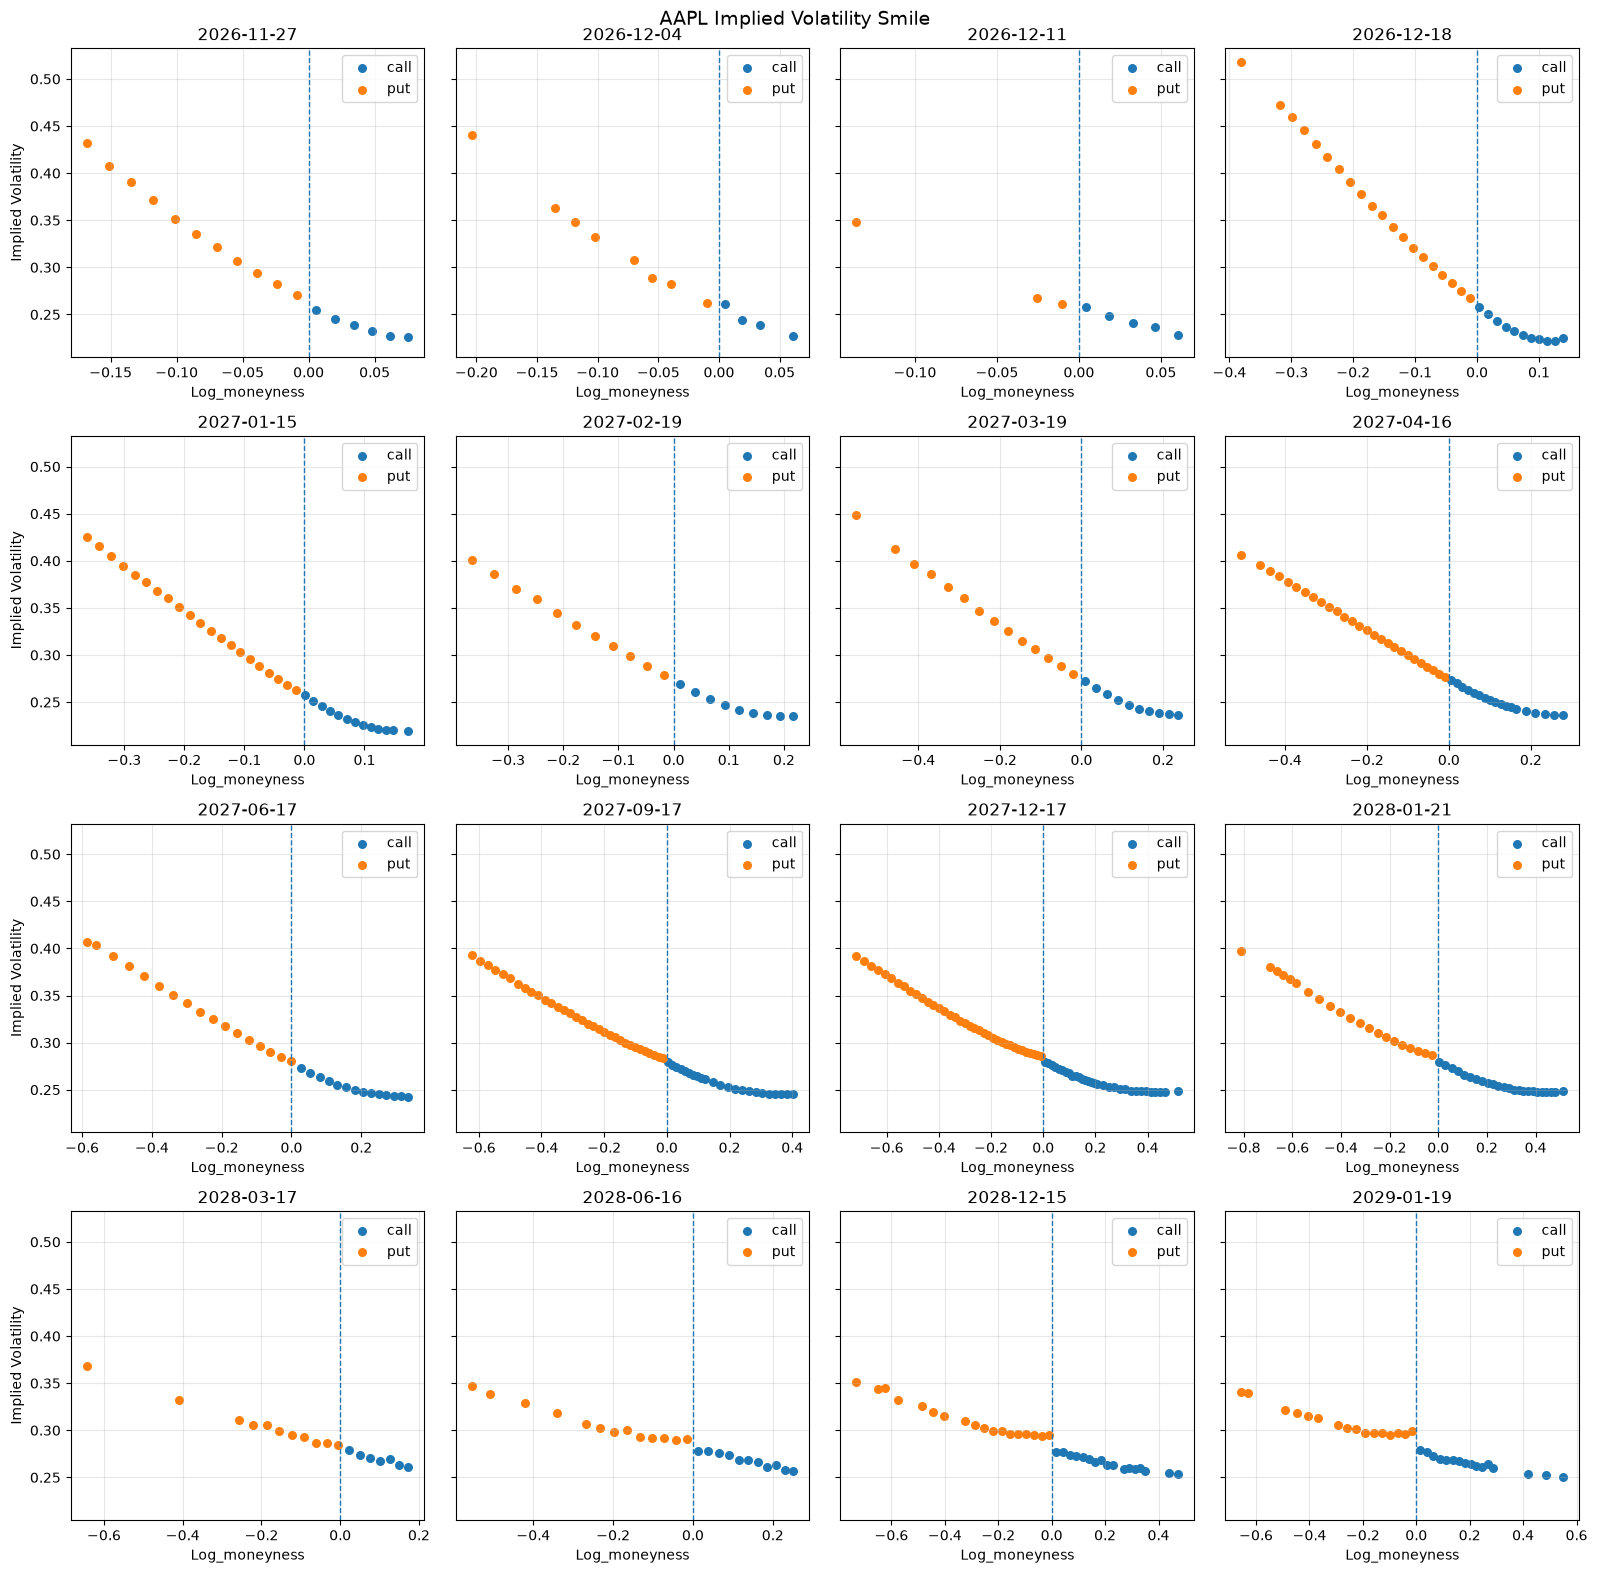

ATM check


,expiration,n,atm_available,k_gap
0,2026-11-27,17,True,0.014599
1,2026-12-04,12,True,0.014599
2,2026-12-11,8,True,0.014599
3,2026-12-18,31,True,0.014599
4,2027-01-15,34,True,0.014599
5,2027-02-19,20,True,0.028988
6,2027-03-19,24,True,0.028988
7,2027-04-16,45,True,0.014389
8,2027-06-17,31,True,0.028171
9,2027-09-17,56,True,0.014185


ATM term structure


,expiration,T,implied_volatility
0,2026-11-27,0.057534,0.260896
1,2026-12-04,0.076712,0.261284
2,2026-12-11,0.095890,0.258601
3,2026-12-18,0.115068,0.259887
4,2027-01-15,0.191781,0.257596
5,2027-02-19,0.287671,0.272890
6,2027-03-19,0.364384,0.274571
7,2027-04-16,0.441096,0.274690
8,2027-06-17,0.610959,0.279978
9,2027-09-17,0.863014,0.279752


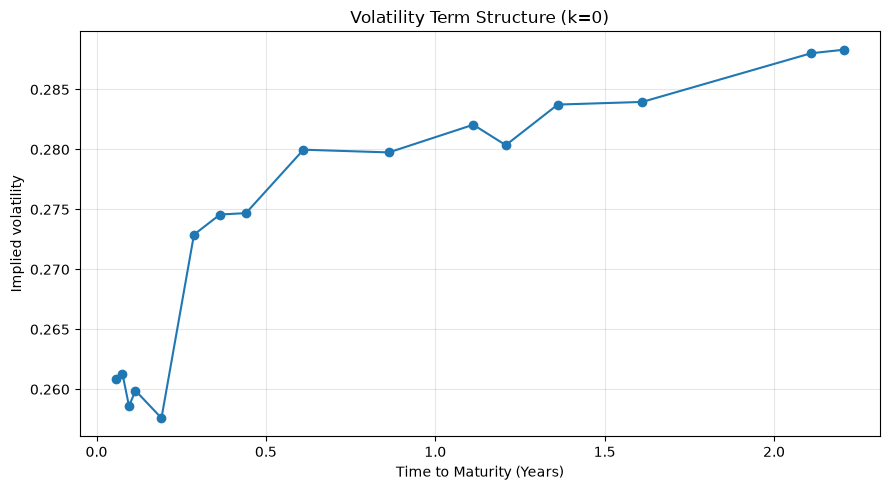

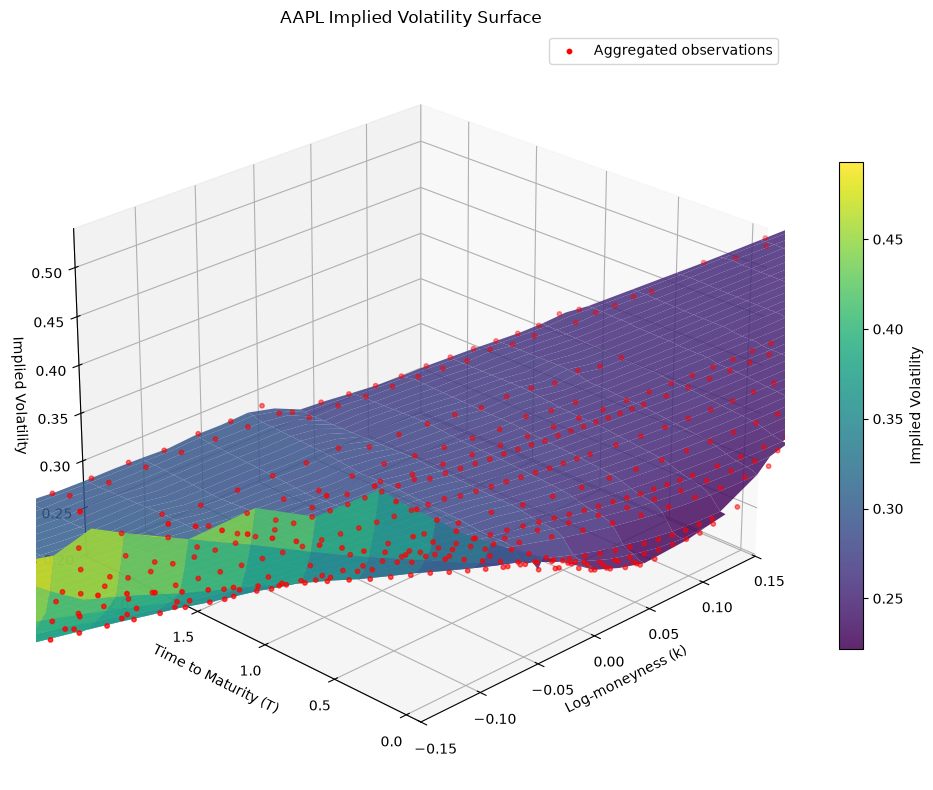

In [6]:
import src.volatility_surface as vs 
import matplotlib.pyplot as plt
import numpy as np 

otm_iv=iv.calculate_iv_surface(otm_options)
SPREAD_LIMIT=0.2
IV_COL='iv_bs'

# Plot smile, max_spread=0.2
fig,axes=vs.plot_smile(otm_iv,spread_limit=SPREAD_LIMIT,iv_col=IV_COL)
fig.savefig('figures/volatility_smile.png',dpi=300,bbox_inches='tight')
plt.show()

# Term structure
## ATM check: whether targeted log_moneyness k=0 can be interpolated between k_1<0 and k_2>0
data=otm_iv[otm_iv['relative_spread']<=SPREAD_LIMIT].copy()

records=[]

for expiration,group in data.groupby('expiration'):
    left=group[group['log_moneyness']<=0].sort_values('log_moneyness').tail(1)

    right=group[group['log_moneyness']>=0].sort_values('log_moneyness').head(1)

    if left.empty or right.empty:
        records.append({
            'expiration':expiration,
            'n':len(group),
            'atm_available':False,
            'k_gap':np.nan
        })
        continue

    k_left=left['log_moneyness'].iloc[0]
    k_right=right['log_moneyness'].iloc[0]

    records.append({
        'expiration':expiration,
        'n':len(group),
        'atm_available':True,
        'k_gap':k_right-k_left
    })

atm_check=pd.DataFrame(records)

print('ATM check')
display(atm_check)


fig, ax, term_structure = vs.plot_term_structure(
    otm_iv,
    target_k=0,
    spread_limit=SPREAD_LIMIT,
    iv_col=IV_COL
)

print('ATM term structure')
display(term_structure)

fig.savefig('figures/term_structure.png',dpi=300,bbox_inches='tight')
plt.show()


# 3D Surface
fig, ax, surface_data = vs.plot_volatility_surface(
    otm_iv,
    spread_limit=SPREAD_LIMIT,
    iv_col=IV_COL,
    grid_size=60
)

# Focus on the near-ATM region
ax.set_xlim(-0.15,0.15)

fig.savefig('figures/volatility_surface.png',dpi=300,bbox_inches='tight')

plt.show()

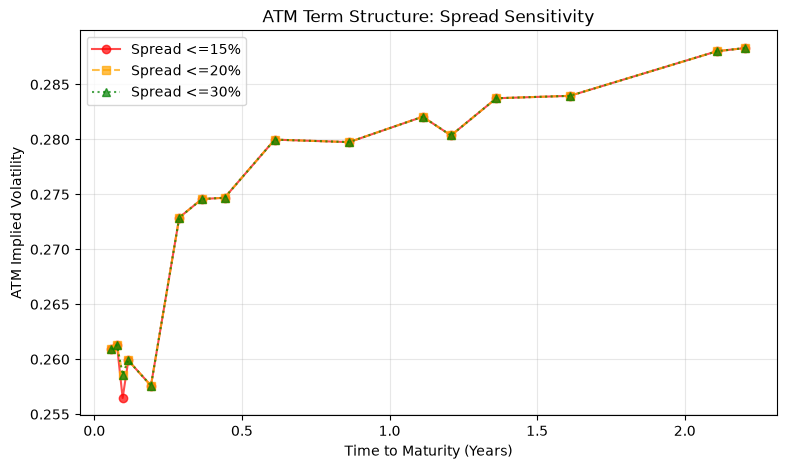

              0.15      0.20      0.30
T                                     
0.057534  0.260896  0.260896  0.260896
0.076712  0.261284  0.261284  0.261284
0.095890  0.256472  0.258601  0.258601
0.115068  0.259887  0.259887  0.259887
0.191781  0.257596  0.257596  0.257596
0.287671  0.272890  0.272890  0.272890
0.364384  0.274571  0.274571  0.274571
0.441096  0.274690  0.274690  0.274690
0.610959  0.279978  0.279978  0.279978
0.863014  0.279752  0.279752  0.279752
1.112329  0.282059  0.282059  0.282059
1.208219  0.280357  0.280357  0.280357
1.361644  0.283741  0.283741  0.283741
1.610959  0.283961  0.283961  0.283961
2.109589  0.288022  0.288022  0.288022
2.205479  0.288313  0.288313  0.288313


In [7]:
# Spread Sensitivity Test
fig,ax=plt.subplots(figsize=(9,5))
styles=[
    ('red','o','-'),
    ('orange','s','--'),
    ('green','^',':')
]
term_results={}

for threshold, (color,marker,linestyle) in zip([0.15,0.2,0.3],styles):

    fig_temp,_,term=vs.plot_term_structure(
        otm_iv,target_k=0,spread_limit=threshold
    )

    term_results[threshold]=term.set_index('T')['implied_volatility']
    plt.close(fig_temp)

    ax.plot(
        term['T'],term['implied_volatility'],label=f'Spread <={threshold:.0%}',
        color=color,marker=marker,linestyle=linestyle,linewidth=1.5,markersize=6,alpha=0.7
    )

ax.set_xlabel('Time to Maturity (Years)')
ax.set_ylabel('ATM Implied Volatility')
ax.set_title('ATM Term Structure: Spread Sensitivity')

ax.legend()
ax.grid(alpha=0.3)

plt.show()

comparision=pd.concat(term_results,axis=1)
print(comparision)

## 6. Conclusion

This project constructed an approximate AAPL implied-volatility surface from a Yahoo Finance option-chain snapshot dated **2026-11-06**. The dataset covers **16 expiration dates**, from **21 to 805 calendar days** after the valuation date. The original option-chain file contained **2,152 contracts**; **1,945** remained after basic cleaning, including **984 OTM contracts** before the relative-spread filter.

The Black–Scholes implied-volatility inversion uses option mid-quotes and Brent's root-finding method. With a 30% relative-spread limit, **1,545 cleaned contracts** were passed to the IV solver and **1,521** received a numerical IV solution, giving a **98.45% success rate**. For the OTM sample, **584 contracts** passed the 30% limit and all 584 produced an IV. The main Smile, ATM-forward Term Structure, and 3D Surface plots use a **20% relative-spread threshold**, retaining **500 OTM observations**.

**Market inputs.** The analysis uses \(S_0=\$342.37\), consistent with the Yahoo Finance regular-market price and the 2026-11-06 15:59 one-minute close of approximately \$342.365. The continuous dividend yield is set to \(q=0.00315\), based on an assumed annual dividend of \$1.08 and rounded for the experiment. Maturity-dependent risk-free rates are obtained from the daily U.S. Treasury yield data using the project's interpolation procedure.

**Main findings.** The volatility smiles show a pronounced **negative equity skew** for most expirations: OTM puts at lower log-moneyness generally have higher implied volatility than OTM calls at higher log-moneyness. The ATM-forward term structure, estimated by linear interpolation between observations bracketing \(k=0\), starts at approximately **26.09%** for the 21-day maturity. It reaches a local low of approximately **25.76%** at 70 days and then generally rises, reaching approximately **28.83%** at 805 days. The term structure is not monotonic and contains local fluctuations. The 3D piecewise-linear surface visualizes the joint variation of implied volatility with log-moneyness and maturity.

**Spread sensitivity.** The OTM sample contains **344, 434, 500, and 584** contracts under 10%, 15%, 20%, and 30% relative-spread limits, respectively. The 20% threshold is used as a practical compromise between quote filtering and cross-maturity coverage; it is not claimed to be a statistically optimal universal threshold. Comparing the ATM-forward term structures under 15%, 20%, and 30% limits gives identical estimates for most maturities. The main exception is **2026-12-11**: the 15% filter gives approximately **25.65%**, while the 20% and 30% filters both give approximately **25.86%**. This is a modest difference, but it also highlights the limited number of quotes available for some short maturities.

**Limitations.** AAPL listed equity options are American-style, whereas the IV calculation uses the European Black–Scholes formula as an approximation. The continuous dividend yield approximates discrete cash dividends. The Treasury inputs are based on quoted par yields rather than a bootstrapped zero-coupon curve; for the 21- and 28-day maturities, which are shorter than the shortest available Treasury tenor, the current interpolation routine uses the first tenor's rate. Although the selected stock reference price agrees closely with the 15:59 stock close, Yahoo does not provide a reliable per-contract timestamp for every option bid and ask, so exact synchronization between the stock and option quotes cannot be guaranteed. Finally, the 3D surface is a linear interpolation of observed IV points, not an arbitrage-free calibration or a forecasting model.

**Takeaway.** The project connects option-pricing theory, numerical root finding, market-data cleaning, spread-based filtering, and volatility visualization. A central practical lesson is that **a successful numerical IV solution does not by itself guarantee a reliable market estimate**. Quote quality, timestamp alignment, model assumptions, and data coverage are all important when interpreting an implied-volatility surface.
